# 04 · Produtos e Sellers Top Performers
**Tech Challenge – Fase 1 · POSTECH Data Analytics** · Trilha: *Crescimento e Receita*

**Perguntas de negócio**
1. Quão concentrada é a receita em poucos produtos e vendedores (sellers)? Qual o risco disso?
2. Quem são os top performers – e eles vendem **bem** (boa avaliação e entrega no prazo) ou apenas **muito**?
3. A base de sellers está crescendo de forma saudável?

**Critério de top performer:** não basta faturar muito. Combinamos **receita**, **nota média das avaliações**
(`review_score`, 1 a 5) e **% de pedidos entregues após o prazo prometido**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from olist_utils import *

set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

In [2]:
t = load_all()
items = analysis_base(t)
R = items["price"].sum()

# Qualidade por pedido: nota média da avaliação e atraso na entrega
nota = t["reviews"].groupby("order_id")["review_score"].mean()
o = t["orders"].set_index("order_id")
atraso = (o["order_delivered_customer_date"] > o["order_estimated_delivery_date"]).where(
    o["order_delivered_customer_date"].notna())
items["nota"] = items["order_id"].map(nota)
items["atrasado"] = items["order_id"].map(atraso).astype(float)
print(f"Pedidos com avaliação: {pct(items.drop_duplicates('order_id')['nota'].notna().mean())} | "
      f"pedidos entregues com atraso: {pct(items.drop_duplicates('order_id')['atrasado'].mean())}")

Pedidos com avaliação: 99,3% | pedidos entregues com atraso: 8,1%


## 1. Concentração: poucos produtos e sellers geram a maior parte da receita

In [3]:
prod = items.groupby("product_id").agg(
    categoria=("product_category_name", "first"), receita=("price", "sum"),
    unidades=("order_item_id", "count"), preco_medio=("price", "mean"),
    sellers=("seller_id", "nunique"), nota=("nota", "mean"),
).sort_values("receita", ascending=False)
sell = items.groupby("seller_id").agg(
    uf=("seller_state", "first"), receita=("price", "sum"), pedidos=("order_id", "nunique"),
    produtos=("product_id", "nunique"), categorias=("product_category_name", "nunique"),
    nota=("nota", "mean"), atraso=("atrasado", "mean"), meses_ativos=("month", "nunique"),
).sort_values("receita", ascending=False)

def share_top(df, q):
    n = max(1, int(len(df) * q))
    return df["receita"].head(n).sum() / df["receita"].sum()

conc = pd.DataFrame({
    "Produtos": [len(prod), share_top(prod, .01), share_top(prod, .10), share_top(prod, .20), gini(prod["receita"])],
    "Sellers": [len(sell), share_top(sell, .01), share_top(sell, .10), share_top(sell, .20), gini(sell["receita"])],
}, index=["quantidade", "receita do top 1%", "receita do top 10%", "receita do top 20%", "índice de Gini"])
conc.T.assign(**{c: conc.T[c].map(pct) for c in conc.index[1:4]}).T

,Produtos,Sellers
quantidade,"32,578.00","3,029.00"
receita do top 1%,"24,5%","25,8%"
receita do top 10%,"60,9%","67,3%"
receita do top 20%,"74,9%","82,5%"
índice de Gini,0.71,0.79


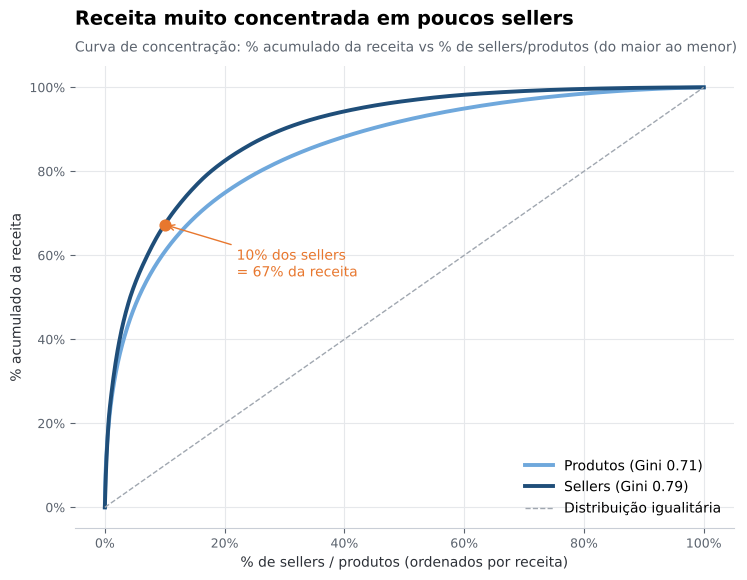

Produtos vendidos uma única vez: 54,9% do catálogo vendido


In [4]:
fig, ax = plt.subplots(figsize=(8.5, 6))
for df, nome, cor in [(prod, "Produtos", COLORS["secondary"]), (sell, "Sellers", COLORS["primary"])]:
    y = np.r_[0, df["receita"].cumsum().values / df["receita"].sum()]
    x = np.linspace(0, 1, len(y))
    ax.plot(x, y, color=cor, lw=2.8, label=f"{nome} (Gini {gini(df['receita']):.2f})")
ax.plot([0, 1], [0, 1], color=COLORS["neutral"], ls="--", lw=1, label="Distribuição igualitária")
top10 = share_top(sell, .10)
ax.scatter([0.10], [top10], color=COLORS["accent"], zorder=5, s=60)
ax.annotate(f"10% dos sellers\n= {pct(top10, 0)} da receita", (0.10, top10), xytext=(0.22, 0.55),
            fontsize=10, color=COLORS["accent"], arrowprops=dict(arrowstyle="->", color=COLORS["accent"]))
ax.set_title("Receita muito concentrada em poucos sellers")
subtitle(ax, "Curva de concentração: % acumulado da receita vs % de sellers/produtos (do maior ao menor)")
axis_pct(ax, "x"); axis_pct(ax, "y")
ax.set_xlabel("% de sellers / produtos (ordenados por receita)")
ax.set_ylabel("% acumulado da receita")
ax.grid(axis="x", visible=True)
ax.legend(loc="lower right")
save(fig, "12_concentracao_sellers_produtos")
plt.show()
print(f"Produtos vendidos uma única vez: {pct((prod['unidades'] == 1).mean())} do catálogo vendido")

**Leitura:** 10% dos sellers (≈ 300 lojas) geram **2/3 da receita**; o top 1% (30 sellers), um quarto.
No catálogo, 55% dos produtos venderam uma única vez – cauda longa típica de marketplace.
A perda de um grande seller tem impacto relevante: **gestão de contas-chave é crítica**.

## 2. Top 10 produtos

In [5]:
top_prod = prod.head(10).copy()
top_prod.index = [f"P{i+1:02d} · {pid[:8]}" for i, pid in enumerate(top_prod.index)]
top_prod["participacao"] = top_prod["receita"] / R
top_prod["participacao"] = top_prod["participacao"].map(lambda v: pct(v, 2))
top_prod[["categoria", "receita", "participacao", "unidades", "preco_medio", "sellers", "nota"]]

,categoria,receita,participacao,unidades,preco_medio,sellers,nota
P01 · bb50f2e2,beleza_saude,"63,885.00","0,47%",195,327.62,1,4.22
P02 · 6cdd5384,beleza_saude,"54,730.20","0,41%",156,350.83,1,4.32
P03 · d6160fb7,pcs,"48,899.34","0,36%",35,"1,397.12",1,4.57
P04 · d1c42706,informatica_acessorios,"46,916.51","0,35%",341,137.59,1,4.20
P05 · 99a4788c,cama_mesa_banho,"42,938.66","0,32%",487,88.17,2,3.90
P06 · 3dd2a171,informatica_acessorios,"41,082.60","0,31%",274,149.94,1,4.21
P07 · 25c38557,bebes,"38,907.32","0,29%",38,"1,023.88",2,2.68
P08 · 5f504b3a,cool_stuff,"37,733.90","0,28%",63,598.95,1,4.56
P09 · 53b36df6,relogios_presentes,"37,683.42","0,28%",323,116.67,3,4.19
P10 · aca2eb7d,moveis_decoracao,"37,608.90","0,28%",527,71.36,1,4.02


In [6]:
cat_top = prod.head(int(len(prod) * .01)).groupby("categoria")["receita"].sum().sort_values(ascending=False)
(cat_top / cat_top.sum()).head(8).map(pct).to_frame("participação no top 1% de produtos")

,participação no top 1% de produtos
categoria,
beleza_saude,"14,8%"
relogios_presentes,"13,5%"
informatica_acessorios,"8,9%"
cool_stuff,"7,0%"
cama_mesa_banho,"6,1%"
ferramentas_jardim,"5,8%"
pcs,"5,7%"
utilidades_domesticas,"3,4%"


**Leitura:** os produtos campeões combinam dois perfis: **alto giro com preço médio** (itens de
cama/mesa/banho, móveis/decoração, beleza com centenas de unidades) e **alto valor** (relógios,
informática, com preço acima de R$ 300). 7 dos 10 têm um único seller – a exclusividade aumenta
o risco de ruptura.

## 3. Top performers de verdade: receita × qualidade

In [7]:
# Considera sellers com volume mínimo para que nota e atraso sejam estáveis
sv = sell[sell["pedidos"] >= 30].copy()
corte_receita = sv["receita"].quantile(0.75)

def segmento(r):
    alto = r["receita"] >= corte_receita
    bom = (r["nota"] >= 4.2) and (r["atraso"] <= 0.08)
    ruim = (r["nota"] < 3.8) or (r["atraso"] > 0.15)
    if alto and bom:
        return "Estrela"
    if alto and ruim:
        return "Grande em risco"
    if alto:
        return "Grande regular"
    if bom:
        return "Promessa"
    return "Demais"

sv["segmento"] = sv.apply(segmento, axis=1)
seg = sv.groupby("segmento").agg(sellers=("receita", "size"), receita=("receita", "sum"),
                                 nota=("nota", "mean"), atraso=("atraso", "mean"))
seg["% receita total"] = seg["receita"] / R
ordem = ["Estrela", "Grande regular", "Grande em risco", "Promessa", "Demais"]
print(f"Sellers com 30+ pedidos: {len(sv)} ({pct(len(sv)/len(sell))} dos sellers, "
      f"{pct(sv['receita'].sum()/R)} da receita) · corte de 'grande' = {brl(corte_receita)}")
seg.loc[ordem]

Sellers com 30+ pedidos: 633 (20,9% dos sellers, 77,1% da receita) · corte de 'grande' = R$ 15.290


,sellers,receita,nota,atraso,% receita total
segmento,,,,,
Estrela,40,"1,591,803.04",4.37,0.05,0.12
Grande regular,91,"4,680,847.32",4.09,0.08,0.35
Grande em risco,28,"940,353.58",3.66,0.11,0.07
Promessa,160,"1,030,602.61",4.40,0.04,0.08
Demais,314,"2,129,166.31",3.93,0.10,0.16


**Regras dos segmentos** (sellers com 30+ pedidos):
* **Estrela:** receita no quartil superior **e** nota ≥ 4,2 **e** atraso ≤ 8%.
* **Grande em risco:** receita no quartil superior **e** (nota < 3,8 **ou** atraso > 15%).
* **Grande regular:** demais sellers do quartil superior.
* **Promessa:** abaixo do quartil superior, mas com nota ≥ 4,2 e atraso ≤ 8% – candidatos a crescer.

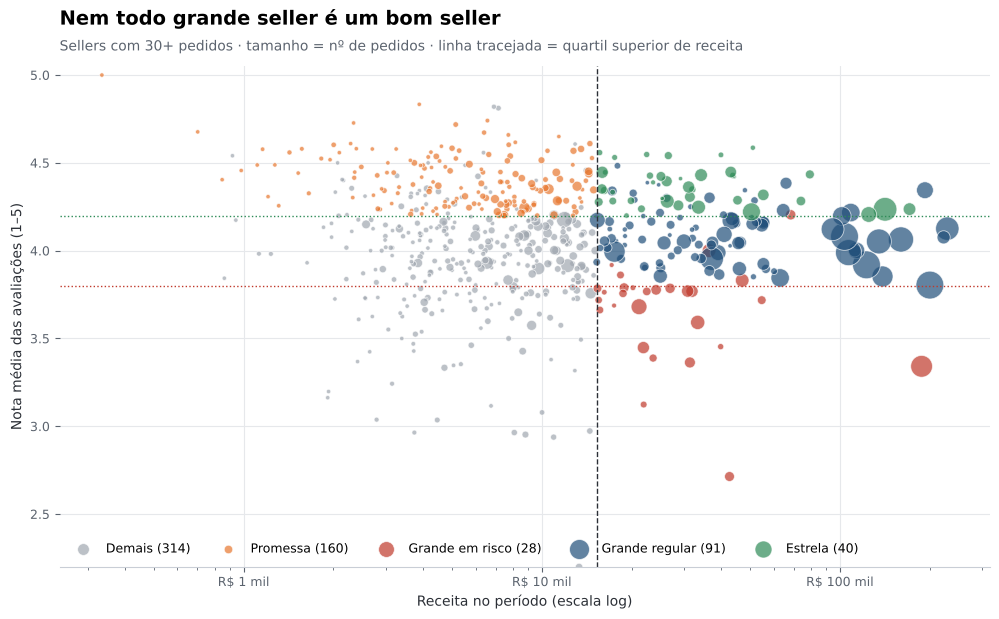

In [8]:
cores_seg = {"Estrela": COLORS["good"], "Grande regular": COLORS["primary"],
             "Grande em risco": COLORS["bad"], "Promessa": COLORS["accent"], "Demais": COLORS["neutral"]}
fig, ax = plt.subplots(figsize=(12, 6.5))
for s_ in ordem[::-1]:
    d = sv[sv["segmento"] == s_]
    ax.scatter(d["receita"], d["nota"], s=np.clip(d["pedidos"] / 4, 10, 400), alpha=0.7,
               color=cores_seg[s_], edgecolor="white", lw=0.6,
               label=f"{s_} ({len(d)})")
ax.set_xscale("log")
ax.axvline(corte_receita, color=COLORS["dark"], ls="--", lw=1)
ax.axhline(4.2, color=COLORS["good"], ls=":", lw=1)
ax.axhline(3.8, color=COLORS["bad"], ls=":", lw=1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(brl_short))
ax.set_xlabel("Receita no período (escala log)")
ax.set_ylabel("Nota média das avaliações (1–5)")
ax.set_title("Nem todo grande seller é um bom seller")
subtitle(ax, "Sellers com 30+ pedidos · tamanho = nº de pedidos · linha tracejada = quartil superior de receita")
ax.grid(axis="x", visible=True)
ax.legend(loc="lower left", ncol=5, fontsize=9)
ax.set_ylim(2.2, 5.05)
save(fig, "13_matriz_sellers")
plt.show()

In [9]:
grandes = sv[sv["receita"] >= corte_receita]
risco = grandes[grandes["segmento"] == "Grande em risco"]
estrela = grandes[grandes["segmento"] == "Estrela"]
print(f"Sellers 'grandes' (quartil superior): {len(grandes)} → {pct(grandes['receita'].sum()/R)} da receita")
print(f"  Estrelas: {len(estrela)} sellers, {pct(estrela['receita'].sum()/R)} da receita, "
      f"nota {estrela['nota'].mean():.2f}, atraso {pct(estrela['atraso'].mean())}")
print(f"  Em risco: {len(risco)} sellers, {pct(risco['receita'].sum()/R)} da receita, "
      f"nota {risco['nota'].mean():.2f}, atraso {pct(risco['atraso'].mean())}")

Sellers 'grandes' (quartil superior): 159 → 53,6% da receita
  Estrelas: 40 sellers, 11,8% da receita, nota 4.37, atraso 4,7%
  Em risco: 28 sellers, 7,0% da receita, nota 3.66, atraso 11,2%


In [10]:
top_sel = sell.head(10).copy()
top_sel["segmento"] = sv["segmento"].reindex(top_sel.index)
top_sel["participacao"] = top_sel["receita"] / R
top_sel.index = [f"S{i+1:02d} · {sid[:8]}" for i, sid in enumerate(top_sel.index)]
top_sel["participacao"] = top_sel["participacao"].map(lambda v: pct(v, 2))
top_sel["atraso"] = top_sel["atraso"].map(pct)
top_sel[["uf", "receita", "participacao", "pedidos", "categorias", "nota", "atraso", "segmento"]]

,uf,receita,participacao,pedidos,categorias,nota,atraso,segmento
S01 · 4869f7a5,SP,"229,237.63","1,70%",1131,10,4.13,"11,6%",Grande regular
S02 · 53243585,BA,"222,776.05","1,66%",358,2,4.08,"4,0%",Grande regular
S03 · 4a3ca931,SP,"200,326.12","1,49%",1804,7,3.80,"11,0%",Grande regular
S04 · fa1c13f2,SP,"192,842.13","1,43%",584,5,4.34,"10,2%",Grande regular
S05 · 7c67e144,SP,"187,923.89","1,40%",982,6,3.34,"9,6%",Grande em risco
S06 · 7e93a43e,SP,"171,184.88","1,27%",331,8,4.24,"5,6%",Estrela
S07 · da8622b1,SP,"160,236.57","1,19%",1314,4,4.06,"7,3%",Grande regular
S08 · 7a67c85e,SP,"141,715.54","1,05%",1159,2,4.24,"5,9%",Estrela
S09 · 1025f0e2,SP,"138,968.55","1,03%",915,4,3.85,"9,2%",Grande regular
S10 · 955fee92,SP,"135,159.70","1,00%",1286,23,4.05,"8,1%",Grande regular


**Leitura:** entre os sellers de maior receita há tanto **estrelas** (nota alta, entrega no prazo) quanto
**grandes em risco** (nota baixa ou muitos atrasos). Os "em risco" geram receita hoje, mas corroem a
reputação da plataforma e a recompra (que já é baixíssima, ~3%). Já as **promessas** – sellers menores com
excelente nota e entrega – são o melhor alvo para impulsionar com visibilidade e campanhas.

## 4. A base de sellers cresce mais rápido que a receita

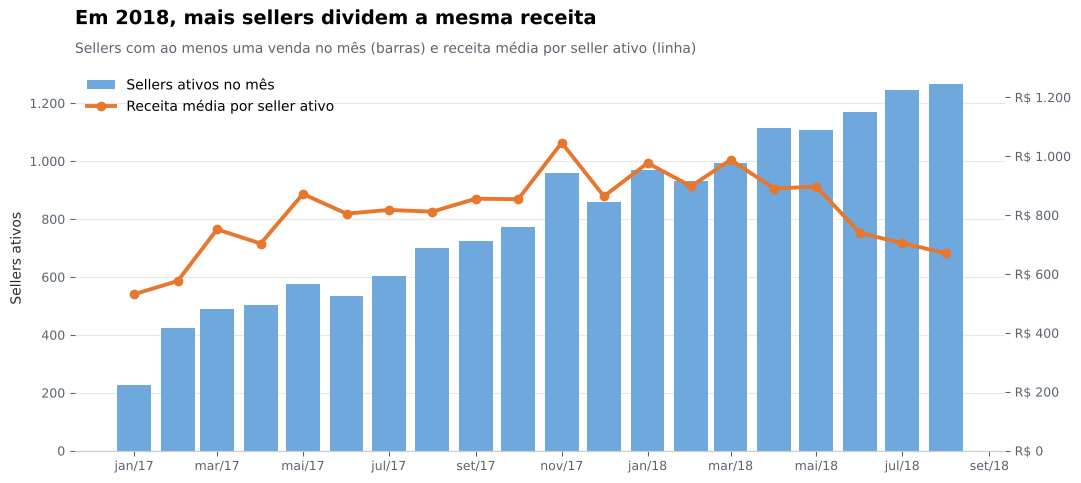

jan→ago/2018: sellers ativos 968 → 1.266 (30,8%); receita por seller R$ 977 → R$ 671 (-31,4%)


In [11]:
mens = items.groupby("month").agg(sellers_ativos=("seller_id", "nunique"), receita=("price", "sum"))
mens["receita_por_seller"] = mens["receita"] / mens["sellers_ativos"]
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(mens.index, mens["sellers_ativos"], width=24, color=COLORS["secondary"], label="Sellers ativos no mês")
axis_int(ax1)
ax1.set_ylabel("Sellers ativos")
ax2 = ax1.twinx()
ax2.plot(mens.index, mens["receita_por_seller"], color=COLORS["accent"], lw=2.8, marker="o",
         label="Receita média por seller ativo")
ax2.set_ylim(0, mens["receita_por_seller"].max() * 1.25)
ax2.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda x, p: f"R$ {x:,.0f}".replace(",", ".")))
ax2.spines["right"].set_visible(False)
ax2.grid(False)
ax1.set_title("Em 2018, mais sellers dividem a mesma receita")
subtitle(ax1, "Sellers com ao menos uma venda no mês (barras) e receita média por seller ativo (linha)")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
month_axis(ax1)
save(fig, "14_sellers_ativos")
plt.show()
j, a_ = mens.loc["2018-01-01"], mens.loc["2018-08-01"]
print(f"jan→ago/2018: sellers ativos {fmt_int(j['sellers_ativos'])} → {fmt_int(a_['sellers_ativos'])} "
      f"({pct(a_['sellers_ativos']/j['sellers_ativos']-1)}); receita por seller "
      f"{brl(j['receita_por_seller'])} → {brl(a_['receita_por_seller'])} "
      f"({pct(a_['receita_por_seller']/j['receita_por_seller']-1)})")

**Leitura:** a Olist continuou atraindo sellers em 2018 (+31% de sellers ativos de jan a ago), mas a
demanda não acompanhou: a receita média por seller caiu ~30%. Isso é um sinal de alerta – sellers que
vendem menos tendem a abandonar a plataforma. **O gargalo atual é demanda (clientes), não oferta.**

## 5. Onde estão os sellers

In [12]:
loc = pd.DataFrame({
    "% sellers": sell["uf"].value_counts(normalize=True),
    "% receita (origem)": sell.groupby("uf")["receita"].sum() / R,
}).fillna(0).sort_values("% receita (origem)", ascending=False)
loc["região"] = loc.index.map(UF_REGIAO)
reg_s = loc.groupby("região")[["% sellers", "% receita (origem)"]].sum().sort_values("% receita (origem)", ascending=False)
reg_c = items.groupby("customer_region")["price"].sum() / R
reg_s["% receita (destino/clientes)"] = reg_c
reg_s

,% sellers,% receita (origem),% receita (destino/clientes)
região,,,
Sudeste,0.74,0.78,0.65
Sul,0.22,0.17,0.14
Nordeste,0.02,0.03,0.11
Centro-Oeste,0.03,0.01,0.06
Norte,0.00,0.00,0.02


**Leitura:** 64% da receita sai de sellers de SP e apenas ~3% de sellers do Nordeste, embora 11% da receita
vá para clientes nordestinos. Quase tudo que o Norte/Nordeste compra viaja milhares de km – o que explica o
frete alto visto no notebook 03. **Atrair sellers locais no Nordeste reduz frete e destrava demanda.**

## Conclusões do notebook
1. **Alta concentração:** 10% dos sellers = 67% da receita (Gini 0,79). Risco de dependência → programa de
   contas-chave.
2. **Top performer ≠ maior faturamento:** parte dos grandes sellers tem nota baixa ou muitos atrasos
   ("grandes em risco"); as "estrelas" e "promessas" devem ganhar prioridade em vitrines e campanhas.
3. **Desequilíbrio oferta × demanda:** sellers ativos +31% em 2018 com receita estável → receita por
   seller −30%.
4. **Oferta concentrada em SP**: sellers do Nordeste são quase inexistentes, reforçando o problema de frete.

➡️ Síntese e recomendações: `05_sintese_recomendacoes.ipynb`